<a href="https://colab.research.google.com/github/Anshu811/HawkEye/blob/main/HAWKeye_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install shapely opencv-python-headless tqdm seaborn


Mounted at /content/drive


In [ ]:
import os
ROOT = '/content/drive/MyDrive/hawkeye'      # Drive pe permanent cheezein
OUT  = '/content/hawkeye'                    # local fast disk (crops yahin banenge)
for d in [ROOT, OUT, f'{ROOT}/eda', '/content/xbd']:
    os.makedirs(d, exist_ok=True)
!nvidia-smi -L ; df -h /content | tail -1

GPU 0: Tesla T4 (UUID: GPU-dff199f9-8434-4144-3320-77b9bcd2a66f)
overlay         113G   43G   71G  38% /


In [ ]:
import os
os.makedirs('/content/xbd', exist_ok=True)

XBD_URL = "https://download.xview2.org/train_images_labels_targets.tar.gz?Expires=1791650779&Signature=MfPi7wR6BKB7~weWWxmVYGE0r21CS5mbT0EagrF9WW9dhAxvu8BEV-za2g2J5rbMm6zwRIYi65rejEQ7de0RYqOcb-umIQ18fQ9LqvP6DbMFbka7frt6uM6HOEy7DWJH~73-WTznk~Vj0JxhEgtbJVBuYyUhVkYx8Xt7x9yYnWzSCZLyeDOCoxlJ1OHFpMmZ-eC9Uqgy7r2SL-2ZXBzXa69zXUWBqFwe0fintZwwHsOsNmW40T0uoh~-nGbx~cbAYRjbNMZ-4vFKF4wgyyXizKcjIi-VXguGh-Y5GoOBPXZephMekoNuBirgtT5Ziu~XoFpL8pwDJCdJnvFaV~aeuw__&Key-Pair-Id=APKAIKGDJB5C3XUL2DXQ"
TAR = '/content/xbd_train.tar.gz'

# 1) Download (interrupt ho to cell dobara chalao, -c se resume hoga)
!wget -c -q --show-progress -O {TAR} "{XBD_URL}"

# 2) Integrity check: output ye hona chahiye -> b37a4ef4ee9c909e2b19d046e49d42ee3965714b
!sha1sum {TAR}

/content/xbd_train. 100%[===================>]   7.81G   228MB/s    in 39s     
b37a4ef4ee9c909e2b19d046e49d42ee3965714b  /content/xbd_train.tar.gz


In [ ]:
TAR = '/content/xbd_train.tar.gz'   # already downloaded and SHA1-verified

# Extract only the images/ and labels/ folders
!tar -xzf {TAR} -C /content/xbd --wildcards '*images/*' '*labels/*'

# Delete the archive to free disk space
!rm -f {TAR}

# Sanity checks
!find /content/xbd -maxdepth 2 -type d
!ls /content/xbd/*/images | head -3
!ls /content/xbd/*/labels | wc -l
!df -h /content | tail -1

/content/xbd
/content/xbd/train
/content/xbd/train/labels
/content/xbd/train/images
guatemala-volcano_00000000_post_disaster.png
guatemala-volcano_00000000_pre_disaster.png
guatemala-volcano_00000001_post_disaster.png
5598
overlay         113G   51G   63G  45% /


In [ ]:
import glob, json
import numpy as np
import pandas as pd
from shapely import wkt
from tqdm.auto import tqdm

# Locate folders (works regardless of the top-level folder name inside the tar)
LBL_DIR = glob.glob('/content/xbd/**/labels', recursive=True)[0]
IMG_DIR = os.path.join(os.path.dirname(LBL_DIR), 'images')

# Damage label mapping; anything else (e.g. "un-classified") becomes -1 and is dropped later
LBL = {'no-damage': 0, 'minor-damage': 1, 'major-damage': 2, 'destroyed': 3}

rows = []
for jp in tqdm(sorted(glob.glob(f'{LBL_DIR}/*_post_disaster.json'))):
    # File name pattern: <disaster>_<tileid>_post_disaster.json
    fn = os.path.basename(jp)
    disaster, tile = fn.split('_')[:2]
    js = json.load(open(jp))
    meta = js.get('metadata', {})
    for f in js['features']['xy']:                      # 'xy' = pixel-coordinate polygons
        p = f['properties']
        if p.get('feature_type') != 'building':
            continue
        minx, miny, maxx, maxy = wkt.loads(f['wkt']).bounds
        rows.append(dict(
            disaster=disaster, tile=tile, uid=p['uid'],
            label=LBL.get(p.get('subtype'), -1),
            cx=(minx + maxx) / 2, cy=(miny + maxy) / 2,   # building centre (pixels)
            bw=maxx - minx, bh=maxy - miny,
            side=max(maxx - minx, maxy - miny),           # longer side of bounding box (pixels)
            off_nadir=meta.get('off_nadir_angle', np.nan)))

df = pd.DataFrame(rows)
df.to_csv(f'{ROOT}/buildings_all.csv', index=False)

print(len(df), 'buildings across', df.disaster.nunique(), 'disasters')
print(df.disaster.value_counts())
print('un-classified buildings:', (df.label == -1).sum())

  0%|          | 0/2799 [00:00<?, ?it/s]

162787 buildings across 10 disasters
disaster
mexico-earthquake      32271
palu-tsunami           31394
hurricane-harvey       23014
hurricane-michael      22686
hurricane-matthew      13939
santa-rosa-wildfire    12950
socal-fire             10475
midwest-flooding        8756
hurricane-florence      6446
guatemala-volcano        856
Name: count, dtype: int64
un-classified buildings: 2993


In [ ]:
# Class counts per disaster (before any cap), to validate the planned val/test split
ct = pd.crosstab(df.disaster, df.label).rename(
    columns={-1: 'unclf', 0: 'No', 1: 'Minor', 2: 'Major', 3: 'Destroyed'})
cls = ['No', 'Minor', 'Major', 'Destroyed']
ct['total'] = ct[cls].sum(axis=1)
ct['Major+Destr'] = ct['Major'] + ct['Destroyed']
ct['MD_%'] = (ct['Major+Destr'] / ct['total'] * 100).round(1)
print(ct.sort_values('Major+Destr', ascending=False))

# Planned split: what would val/test contain after the 6000-per-disaster cap?
TEST_D = {'hurricane-matthew', 'midwest-flooding', 'mexico-earthquake'}
VAL_D  = {'hurricane-florence', 'socal-fire'}
CAP = 6000
def est(names):
    # expected Major+Destroyed after a random cap = MD share x min(total, CAP)
    return int(sum(ct.loc[n, 'Major+Destr'] / ct.loc[n, 'total'] * min(ct.loc[n, 'total'], CAP) for n in names))
print('Estimated Major+Destroyed after cap -> val:', est(VAL_D), '| test:', est(TEST_D))

label                unclf     No  Minor  Major  Destroyed  total  \
disaster                                                            
hurricane-harvey       289  11423   2663   8238        401  22725   
palu-tsunami           401  25455      1    571       4966  30993   
hurricane-matthew      784   2515   6548   1945       2147  13155   
santa-rosa-wildfire     53   9285     78     63       3471  12897   
hurricane-michael      232  14588   5207   1902        757  22454   
socal-fire             374   8638     83     51       1329  10101   
hurricane-florence     326   4689    132   1245         54   6120   
midwest-flooding       285   8128    149    119         75   8471   
guatemala-volcano      174    639      9      9         25    682   
mexico-earthquake       75  32066    110     18          2  32196   

label                Major+Destr  MD_%  
disaster                                
hurricane-harvey            8639  38.0  
palu-tsunami                5537  17.9  
hurrica

In [ ]:
import cv2
from concurrent.futures import ProcessPoolExecutor

SEED = 42
S = 224               # final crop size (ViT-B/16 -> 14x14 tokens)
PAD = 0.25            # 25% context padding around each building box
MIN_SIDE = 64         # minimum crop side in pixels before resizing (small buildings get upsampled)
MIN_BLDG = 16         # drop buildings smaller than this (pixels)
MAX_PER_DIS = 6000    # random cap per disaster; keeps the natural class imbalance

# Disaster-wise split (no disaster appears in more than one split)
TEST_D = {'hurricane-matthew', 'midwest-flooding', 'mexico-earthquake'}
VAL_D  = {'hurricane-florence', 'socal-fire'}
assert (TEST_D | VAL_D) <= set(df.disaster), f"Check names: {sorted(df.disaster.unique())}"

df['split'] = np.where(df.disaster.isin(TEST_D), 'test',
              np.where(df.disaster.isin(VAL_D), 'val', 'train'))

# Keep labelled, not-too-small buildings, then cap each disaster randomly
ok = df[(df.label >= 0) & (df.side >= MIN_BLDG)]
sel = pd.concat([g.sample(min(len(g), MAX_PER_DIS), random_state=SEED)
                 for _, g in ok.groupby('disaster')])
sel['stem'] = sel.disaster + '_' + sel.tile + '_' + sel.uid

for sp in ['train', 'val', 'test']:
    os.makedirs(f'{OUT}/crops/{sp}', exist_ok=True)

def crop_sq(img, cx, cy, s):
    """Square crop centred at (cx, cy) with side s; areas outside the tile are zero-padded."""
    s = int(round(s)); x0 = int(round(cx - s / 2)); y0 = int(round(cy - s / 2))
    H, W = img.shape[:2]
    out = np.zeros((s, s, 3), np.uint8)
    xa, ya, xb, yb = max(x0, 0), max(y0, 0), min(x0 + s, W), min(y0 + s, H)
    if xb > xa and yb > ya:
        out[ya - y0:yb - y0, xa - x0:xb - x0] = img[ya:yb, xa:xb]
    return out

def work(args):
    """Crop every selected building of one tile from BOTH pre and post images (same box)."""
    d, t, recs = args
    pre  = cv2.imread(f'{IMG_DIR}/{d}_{t}_pre_disaster.png')
    post = cv2.imread(f'{IMG_DIR}/{d}_{t}_post_disaster.png')
    if pre is None or post is None:
        return 0
    n = 0
    for uid, cx, cy, side, sp in recs:
        s = max(side * (1 + 2 * PAD), MIN_SIDE)
        interp = cv2.INTER_AREA if s > S else cv2.INTER_CUBIC   # shrink vs upsample
        for tag, im in (('pre', pre), ('post', post)):
            c = cv2.resize(crop_sq(im, cx, cy, s), (S, S), interpolation=interp)
            cv2.imwrite(f'{OUT}/crops/{sp}/{d}_{t}_{uid}_{tag}.jpg', c,
                        [cv2.IMWRITE_JPEG_QUALITY, 95])
        n += 1
    return n

# One task per tile so each large PNG is read only once
tasks = [(d, t, g[['uid', 'cx', 'cy', 'side', 'split']].values.tolist())
         for (d, t), g in sel.groupby(['disaster', 'tile'])]

with ProcessPoolExecutor(os.cpu_count()) as ex:
    done = sum(tqdm(ex.map(work, tasks, chunksize=8), total=len(tasks)))

print('crops created:', done, '/', len(sel))
sel.to_csv(f'{OUT}/meta.csv', index=False)

  0%|          | 0/2139 [00:00<?, ?it/s]

crops created: 53936 / 53936


In [ ]:
# Verify that every selected building has both a pre and a post crop on disk
import glob
n_files = {sp: len(glob.glob(f'{OUT}/crops/{sp}/*.jpg')) for sp in ['train', 'val', 'test']}
print('JPEG files per split:', n_files, '| total:', sum(n_files.values()))
print('Expected (2 per building):', 2 * len(sel))
print(sel.split.value_counts().to_dict())

# Pack all crops into one uncompressed tar (JPEGs are already compressed) and copy metadata
!tar -cf {ROOT}/crops.tar -C {OUT} crops
!cp {OUT}/meta.csv {ROOT}/meta.csv
!ls -lh {ROOT}
!du -sh {OUT}/crops

# To restore in a new session:
# !tar -xf /content/drive/MyDrive/hawkeye/crops.tar -C /content/hawkeye
# !cp /content/drive/MyDrive/hawkeye/meta.csv /content/hawkeye/

JPEG files per split: {'train': 49048, 'val': 22824, 'test': 36000} | total: 107872
Expected (2 per building): 107872
{'train': 24524, 'test': 18000, 'val': 11412}
total 1.3G
-rw------- 1 root root  26M Oct 10 16:54 buildings_all.csv
-rw------- 1 root root 1.2G Oct 10 17:02 crops.tar
drwx------ 2 root root 4.0K Oct 10 15:52 eda
-rw------- 1 root root  13M Oct 10 17:02 meta.csv
1.4G	/content/hawkeye/crops


label
No           73.49
Minor         9.37
Major         8.86
Destroyed     8.28
Name: count, dtype: float64
Imbalance ratio (max/min): 8.9 | Major+Destroyed %: 17.14


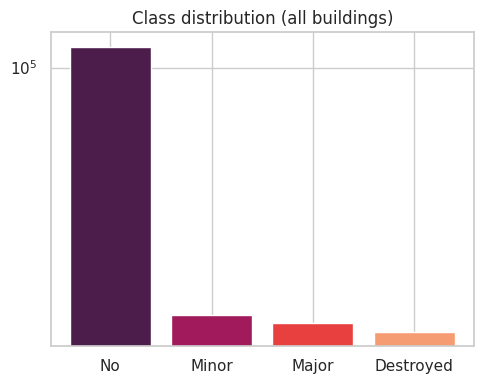

                       No  Minor  Major  Destroyed      n
disaster                                                 
guatemala-volcano    93.7    1.3    1.3        3.7    682
hurricane-florence   76.6    2.2   20.3        0.9   6120
hurricane-harvey     50.3   11.7   36.3        1.8  22725
hurricane-matthew    19.1   49.8   14.8       16.3  13155
hurricane-michael    65.0   23.2    8.5        3.4  22454
mexico-earthquake    99.6    0.3    0.1        0.0  32196
midwest-flooding     96.0    1.8    1.4        0.9   8471
palu-tsunami         82.1    0.0    1.8       16.0  30993
santa-rosa-wildfire  72.0    0.6    0.5       26.9  12897
socal-fire           85.5    0.8    0.5       13.2  10101


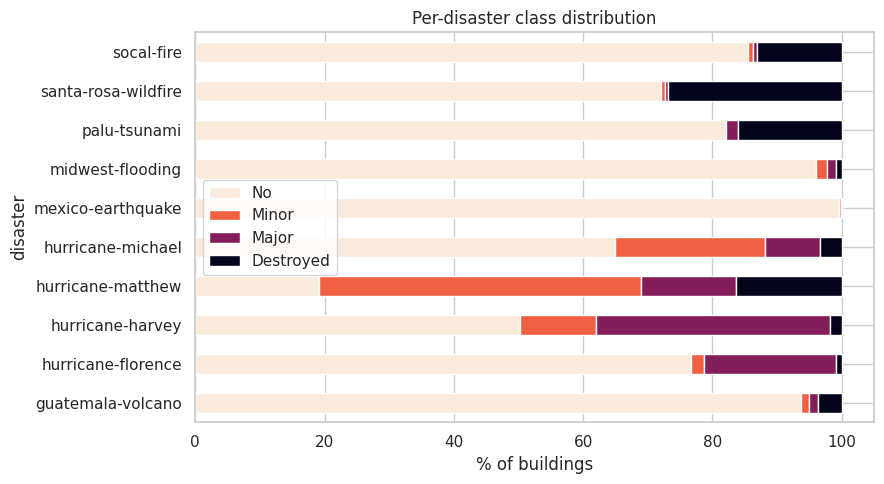

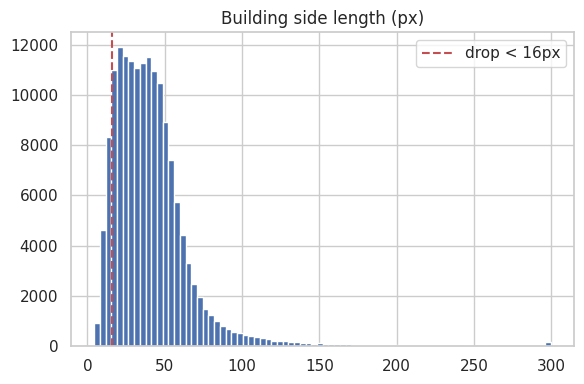

buildings < MIN_BLDG px: 15459 (9.7%) | un-classified (dropped): 2993


  0%|          | 0/1298 [00:00<?, ?it/s]

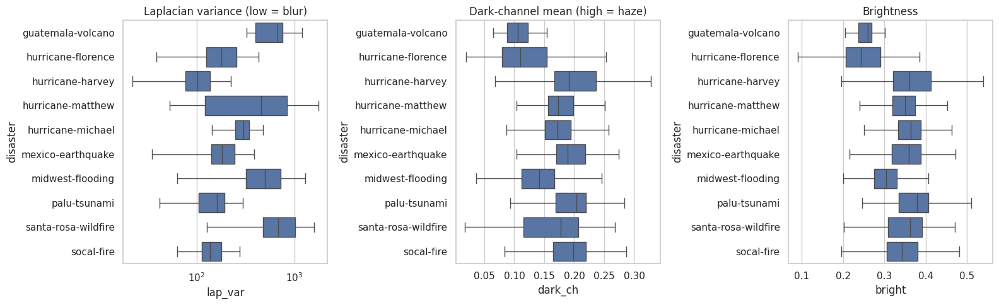

                     lap_var  dark_ch  bright
disaster                                     
guatemala-volcano    666.346    0.106   0.259
hurricane-florence   180.055    0.110   0.244
hurricane-harvey     102.533    0.191   0.361
hurricane-matthew    458.781    0.173   0.350
hurricane-michael    299.413    0.172   0.363
mexico-earthquake    183.317    0.189   0.358
midwest-flooding     495.223    0.141   0.305
palu-tsunami         161.467    0.203   0.379
santa-rosa-wildfire  681.944    0.177   0.362
socal-fire           137.773    0.199   0.342
Median off-nadir angle per disaster:
 disaster
guatemala-volcano      22.0
hurricane-florence     28.0
hurricane-harvey       42.9
hurricane-matthew      29.8
hurricane-michael      28.9
mexico-earthquake      34.4
midwest-flooding       15.4
palu-tsunami           36.4
santa-rosa-wildfire    21.4
socal-fire             32.7
Name: off_nadir, dtype: float64


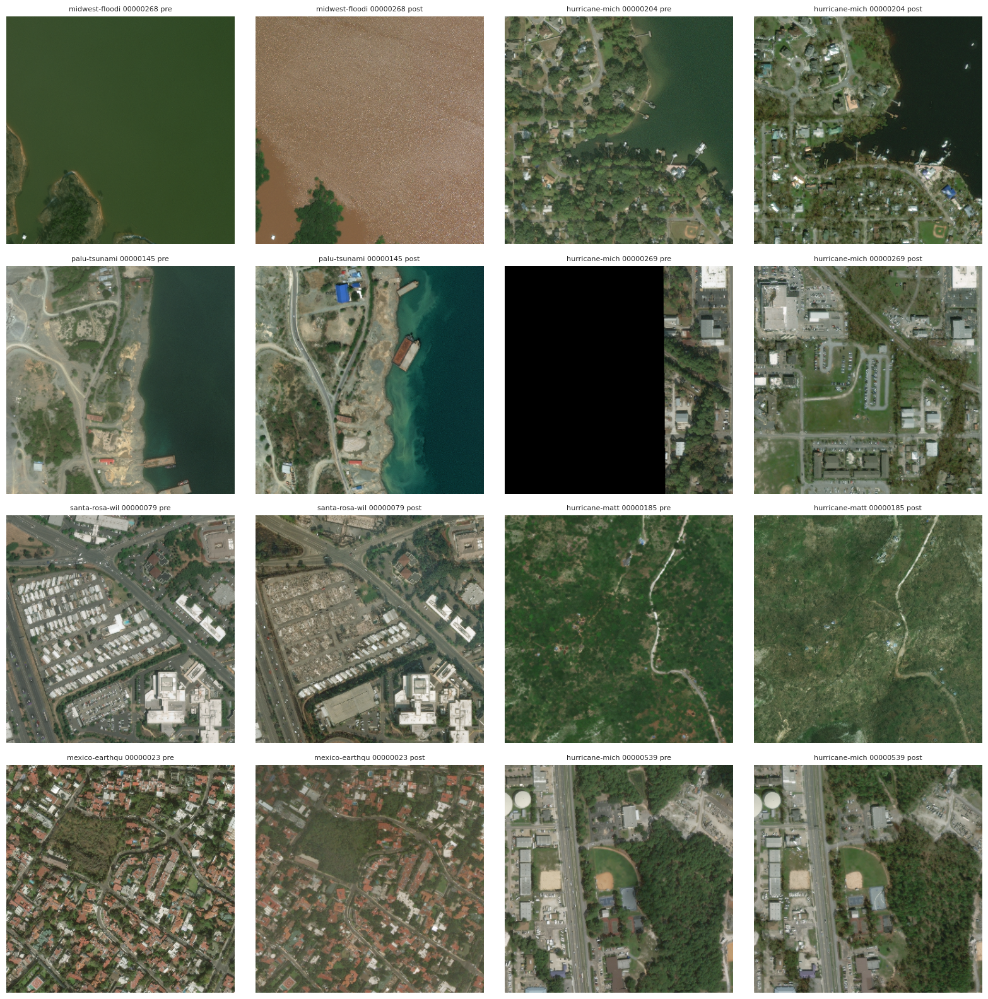

Neighbour label agreement: observed=0.892 | shuffled baseline=0.659 | ratio=1.35x


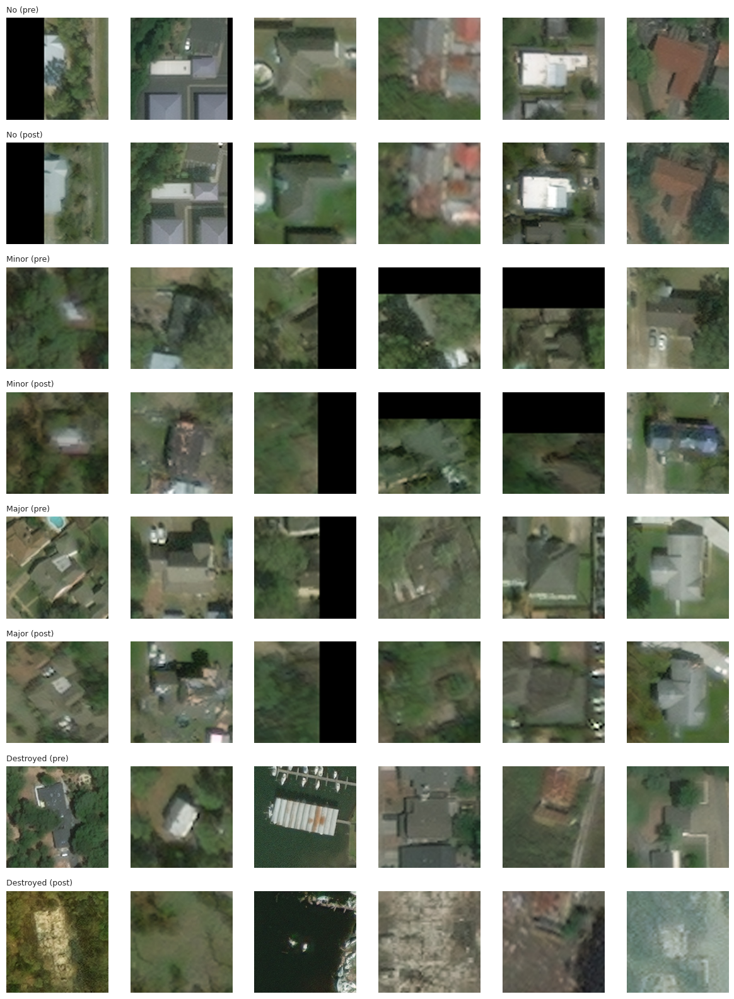

          No  Minor  Major  Destroyed  Major+Destr
split                                             
test   12936   3246   1002        816         1818
train  16606   2254   2867       2797         5664
val     9380    158   1122        752         1874
label                  No  Minor  Major  Destroyed
disaster                                          
guatemala-volcano     494      7      6         17
hurricane-florence   4161    118   1089         44
hurricane-harvey     3006    722   2179         93
hurricane-matthew    1198   3122    916        764
hurricane-michael    3821   1494    528        157
mexico-earthquake    5974     23      2          1
midwest-flooding     5764    101     84         51
palu-tsunami         4991      0    129        880
santa-rosa-wildfire  4294     31     25       1650
socal-fire           5219     40     33        708


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
sns.set_theme(style='whitegrid')

NAMES = ['No', 'Minor', 'Major', 'Destroyed']
EDA = f'{ROOT}/eda'
al = df[df.label >= 0].copy()          # all labelled buildings (before the per-disaster cap)

# ---- 1) Class distribution and imbalance ratio
cnt = al.label.value_counts().sort_index()
print((cnt / cnt.sum() * 100).round(2).rename(dict(enumerate(NAMES))))
print('Imbalance ratio (max/min):', round(cnt.max() / cnt.min(), 1),
      '| Major+Destroyed %:', round(cnt[[2, 3]].sum() / cnt.sum() * 100, 2))
plt.figure(figsize=(5, 4))
plt.bar(NAMES, cnt.values, color=sns.color_palette('rocket', 4))
plt.yscale('log'); plt.title('Class distribution (all buildings)'); plt.tight_layout()
plt.savefig(f'{EDA}/1_class_dist.png', dpi=150); plt.show()

# ---- 2) Per-disaster class distribution
pdist = pd.crosstab(al.disaster, al.label, normalize='index') * 100
pdist.columns = NAMES
print(pdist.round(1).assign(n=al.disaster.value_counts()))
pdist.plot(kind='barh', stacked=True, figsize=(9, 5), colormap='rocket_r')
plt.xlabel('% of buildings'); plt.title('Per-disaster class distribution'); plt.tight_layout()
plt.savefig(f'{EDA}/2_per_disaster.png', dpi=150); plt.show()

# ---- 3) Building size distribution (pixels)
plt.figure(figsize=(6, 4))
plt.hist(al.side.clip(upper=300), bins=80)
plt.axvline(MIN_BLDG, color='r', ls='--', label=f'drop < {MIN_BLDG}px'); plt.legend()
plt.title('Building side length (px)'); plt.tight_layout()
plt.savefig(f'{EDA}/3_size.png', dpi=150); plt.show()
print('buildings < MIN_BLDG px:', (al.side < MIN_BLDG).sum(),
      f'({(al.side < MIN_BLDG).mean() * 100:.1f}%)',
      '| un-classified (dropped):', (df.label == -1).sum())

# ---- 4) Natural image-quality statistics (tile level, post-disaster images)
def tile_quality(args):
    d, t = args
    im = cv2.imread(f'{IMG_DIR}/{d}_{t}_post_disaster.png')
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    return dict(disaster=d,
                lap_var=cv2.Laplacian(g, cv2.CV_64F).var(),                                   # low = blurry
                dark_ch=cv2.erode(im.min(axis=2), np.ones((15, 15), np.uint8)).mean() / 255,  # high = hazy
                bright=g.mean() / 255)

tiles = al[['disaster', 'tile']].drop_duplicates()
tiles = pd.concat([g.sample(min(len(g), 150), random_state=0) for _, g in tiles.groupby('disaster')])
with ProcessPoolExecutor(os.cpu_count()) as ex:
    q = pd.DataFrame(list(tqdm(ex.map(tile_quality, list(map(tuple, tiles.values))), total=len(tiles))))

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, c, t in zip(ax, ['lap_var', 'dark_ch', 'bright'],
                   ['Laplacian variance (low = blur)', 'Dark-channel mean (high = haze)', 'Brightness']):
    sns.boxplot(data=q, y='disaster', x=c, ax=a, showfliers=False); a.set_title(t)
    if c == 'lap_var': a.set_xscale('log')
plt.tight_layout(); plt.savefig(f'{EDA}/4_quality.png', dpi=150); plt.show()
print(q.groupby('disaster').median().round(3))
print('Median off-nadir angle per disaster:\n', al.groupby('disaster').off_nadir.median().round(1))

# ---- 5) Pre/post alignment check: inspect these 8 random tiles visually
rs = tiles.sample(8, random_state=1)
fig, ax = plt.subplots(4, 4, figsize=(16, 16))
for i, (d, t) in enumerate(zip(rs.disaster, rs.tile)):
    for j, tag in enumerate(['pre', 'post']):
        im = cv2.cvtColor(cv2.imread(f'{IMG_DIR}/{d}_{t}_{tag}_disaster.png'), cv2.COLOR_BGR2RGB)
        a = ax[i // 2, (i % 2) * 2 + j]
        a.imshow(cv2.resize(im, (384, 384))); a.axis('off')
        a.set_title(f'{d[:14]} {t} {tag}', fontsize=8)
plt.tight_layout(); plt.savefig(f'{EDA}/5_alignment.png', dpi=120); plt.show()

# ---- 6) Spatial autocorrelation: do neighbouring buildings share damage labels?
def knn_agree(d, col, k=5):
    """Fraction of k nearest neighbours (same tile) that have the same label."""
    num = tot = 0
    for _, g in d.groupby(['disaster', 'tile']):
        if len(g) <= k:
            continue
        xy = g[['cx', 'cy']].values; l = g[col].values
        idx = cKDTree(xy).query(xy, k=k + 1)[1][:, 1:]    # drop self
        num += (l[idx] == l[:, None]).sum(); tot += idx.size
    return num / tot

# Baseline: shuffle labels within each disaster (keeps class mix, destroys spatial structure)
al['perm'] = al.groupby('disaster').label.transform(lambda s: s.sample(frac=1, random_state=0).values)
obs, base = knn_agree(al, 'label'), knn_agree(al, 'perm')
print(f'Neighbour label agreement: observed={obs:.3f} | shuffled baseline={base:.3f} | ratio={obs / base:.2f}x')

# ---- 7) Sample crops per class (top row = pre, bottom row = post)
tr = sel[sel.split == 'train']
fig, ax = plt.subplots(8, 6, figsize=(12, 16))
for c in range(4):
    sm = tr[tr.label == c].sample(6, random_state=0)
    for j, stem in enumerate(sm.stem):
        for r, tag in enumerate(['pre', 'post']):
            im = cv2.cvtColor(cv2.imread(f'{OUT}/crops/train/{stem}_{tag}.jpg'), cv2.COLOR_BGR2RGB)
            a = ax[c * 2 + r, j]; a.imshow(im); a.axis('off')
            if j == 0: a.set_title(f'{NAMES[c]} ({tag})', fontsize=9, loc='left')
plt.tight_layout(); plt.savefig(f'{EDA}/7_samples.png', dpi=120); plt.show()

# ---- 8) Split sufficiency: Major+Destroyed counts in train / val / test
tab = pd.crosstab(sel.split, sel.label); tab.columns = NAMES
tab['Major+Destr'] = tab['Major'] + tab['Destroyed']
print(tab)
print(pd.crosstab(sel.disaster, sel.label).rename(columns=dict(enumerate(NAMES))))

In [ ]:
import shutil

# ---- 1) Share of buildings dropped for being < MIN_BLDG px (uses df already in memory)
tmp = df[df.label >= 0].assign(dropped=lambda x: x.side < MIN_BLDG)
print('Dropped % by class:\n',
      (tmp.groupby('label').dropped.mean() * 100).round(1).rename(dict(enumerate(NAMES))))
print('\nDropped % by disaster:\n', (tmp.groupby('disaster').dropped.mean() * 100).round(1))

# ---- 2) Fraction of black (no-data / zero-padded) pixels in every crop, pre and post
def black_frac(args):
    sp, stem = args
    out = []
    for tag in ('pre', 'post'):
        im = cv2.imread(f'{OUT}/crops/{sp}/{stem}_{tag}.jpg')
        out.append(float((im.max(axis=2) <= 5).mean()))   # all channels ~0 => black
    return out

jobs = list(zip(sel.split, sel.stem))
with ProcessPoolExecutor(os.cpu_count()) as ex:
    res = list(tqdm(ex.map(black_frac, jobs, chunksize=256), total=len(jobs)))
sel[['black_pre', 'black_post']] = np.array(res)
sel['black_max'] = sel[['black_pre', 'black_post']].max(axis=1)

print()
for thr in (0.10, 0.25, 0.50):
    print(f'crops with black_max > {thr:.2f}: {(sel.black_max > thr).sum()} '
          f'({(sel.black_max > thr).mean() * 100:.2f}%)')
print('pre mostly black but post fine:', ((sel.black_pre > 0.5) & (sel.black_post <= 0.5)).sum())

sel['bad'] = sel.black_max > 0.5      # more than half the crop has no information
print('\nBad crop % by class:\n',
      (sel.groupby('label').bad.mean() * 100).round(2).rename(dict(enumerate(NAMES))))
print('\nBad crop % by disaster:\n', (sel.groupby('disaster').bad.mean() * 100).round(2))

# ---- 3) Clean metadata (crops stay on disk; training will read meta_clean.csv)
clean = sel[~sel.bad].drop(columns='bad')
clean.to_csv(f'{OUT}/meta_clean.csv', index=False)
shutil.copy(f'{OUT}/meta_clean.csv', f'{ROOT}/meta_clean.csv')
print('\nbuildings:', len(sel), '->', len(clean))
tab = pd.crosstab(clean.split, clean.label); tab.columns = NAMES
tab['Major+Destr'] = tab['Major'] + tab['Destroyed']
print(tab)

Dropped % by class:
 label
No            9.2
Minor         8.9
Major         5.4
Destroyed    19.4
Name: dropped, dtype: float64

Dropped % by disaster:
 disaster
guatemala-volcano      23.2
hurricane-florence     11.6
hurricane-harvey        2.8
hurricane-matthew      19.1
hurricane-michael       6.8
mexico-earthquake       8.3
midwest-flooding       11.3
palu-tsunami           15.2
santa-rosa-wildfire     4.8
socal-fire              9.5
Name: dropped, dtype: float64


  0%|          | 0/53936 [00:00<?, ?it/s]


crops with black_max > 0.10: 8464 (15.69%)
crops with black_max > 0.25: 5051 (9.36%)
crops with black_max > 0.50: 114 (0.21%)
pre mostly black but post fine: 4

Bad crop % by class:
 label
No           0.24
Minor        0.11
Major        0.16
Destroyed    0.16
Name: bad, dtype: float64

Bad crop % by disaster:
 disaster
guatemala-volcano      0.00
hurricane-florence     0.18
hurricane-harvey       0.32
hurricane-matthew      0.10
hurricane-michael      0.13
mexico-earthquake      0.53
midwest-flooding       0.20
palu-tsunami           0.13
santa-rosa-wildfire    0.18
socal-fire             0.13
Name: bad, dtype: float64

buildings: 53936 -> 53822
          No  Minor  Major  Destroyed  Major+Destr
split                                             
test   12891   3242   1002        815         1817
train  16572   2252   2863       2791         5654
val     9366    158   1118        752         1870


In [ ]:
import shutil

# ---- 0) New, lower size threshold
MIN_BLDG = 10

# What each threshold would drop, per class (df is already in memory)
lab = df[df.label >= 0]
print('Dropped % by class at different thresholds:')
print(pd.DataFrame({t: (lab.assign(d=lab.side < t).groupby('label').d.mean() * 100).round(1)
                    for t in (8, 10, 12, 16)}).rename(index=dict(enumerate(NAMES))))

# ---- 1) Wipe old crops (otherwise stale files from the previous selection would remain)
shutil.rmtree(f'{OUT}/crops', ignore_errors=True)
for sp in ['train', 'val', 'test']:
    os.makedirs(f'{OUT}/crops/{sp}', exist_ok=True)

# ---- 2) Re-select buildings (same disaster split, same cap, same seed)
ok = df[(df.label >= 0) & (df.side >= MIN_BLDG)]
sel = pd.concat([g.sample(min(len(g), MAX_PER_DIS), random_state=SEED)
                 for _, g in ok.groupby('disaster')])
sel['stem'] = sel.disaster + '_' + sel.tile + '_' + sel.uid

# ---- 3) Re-create crops (one task per tile)
tasks = [(d, t, g[['uid', 'cx', 'cy', 'side', 'split']].values.tolist())
         for (d, t), g in sel.groupby(['disaster', 'tile'])]
with ProcessPoolExecutor(os.cpu_count()) as ex:
    done = sum(tqdm(ex.map(work, tasks, chunksize=8), total=len(tasks)))
print('crops created:', done, '/', len(sel))

# ---- 4) Black (no-data) check, same rule as before: drop crops that are > 50% black
jobs = list(zip(sel.split, sel.stem))
with ProcessPoolExecutor(os.cpu_count()) as ex:
    res = list(tqdm(ex.map(black_frac, jobs, chunksize=256), total=len(jobs)))
sel[['black_pre', 'black_post']] = np.array(res)
sel['black_max'] = sel[['black_pre', 'black_post']].max(axis=1)
sel['bad'] = sel.black_max > 0.5
print('bad crops:', int(sel.bad.sum()), f'({sel.bad.mean() * 100:.2f}%)')

# ---- 5) Save metadata (meta.csv = everything selected, meta_clean.csv = bad crops removed)
clean = sel[~sel.bad].drop(columns='bad')
sel.to_csv(f'{OUT}/meta.csv', index=False)
clean.to_csv(f'{OUT}/meta_clean.csv', index=False)

# ---- 6) Verify file count, then back up to Drive
n_files = sum(len(glob.glob(f'{OUT}/crops/{sp}/*.jpg')) for sp in ['train', 'val', 'test'])
print('JPEG files:', n_files, '| expected:', 2 * len(sel))
!tar -cf {ROOT}/crops.tar -C {OUT} crops
!cp {OUT}/meta.csv {OUT}/meta_clean.csv {ROOT}/
!ls -lh {ROOT}

# ---- 7) Final summary on the clean set
tab = pd.crosstab(clean.split, clean.label); tab.columns = NAMES
tab['Major+Destr'] = tab['Major'] + tab['Destroyed']
print(tab)
print(pd.crosstab(clean.disaster, clean.label).rename(columns=dict(enumerate(NAMES))))

Dropped % by class at different thresholds:
            8    10   12    16
label                         
No         0.5  1.7  3.6   9.2
Minor      0.3  1.1  2.8   8.9
Major      0.3  0.9  2.0   5.4
Destroyed  1.3  4.3  8.3  19.4


  0%|          | 0/2163 [00:00<?, ?it/s]

crops created: 54586 / 54586


  0%|          | 0/54586 [00:00<?, ?it/s]

bad crops: 129 (0.24%)
JPEG files: 109172 | expected: 109172
total 1.3G
-rw------- 1 root root  26M Oct 10 16:54 buildings_all.csv
-rw------- 1 root root 1.3G Oct 10 17:24 crops.tar
drwx------ 2 root root 4.0K Oct 10 17:05 eda
-rw------- 1 root root  14M Oct 10 17:24 meta_clean.csv
-rw------- 1 root root  14M Oct 10 17:24 meta.csv
          No  Minor  Major  Destroyed  Major+Destr
split                                             
test   12871   3128    963        977         1940
train  16689   2189   2803       2906         5709
val     9704    177   1233        817         2050
label                  No  Minor  Major  Destroyed
disaster                                          
guatemala-volcano     598      8      8         21
hurricane-florence   4557    127   1206         50
hurricane-harvey     3017    729   2126        113
hurricane-matthew    1197   2987    880        924
hurricane-michael    3880   1412    506        192
mexico-earthquake    5937     27      2          1
midw

In [ ]:
!rm -rf /content/xbd
!df -h /content | tail -1

overlay         113G   45G   68G  40% /


{'test': 0.491, 'train': 0.403, 'val': 0.501} | rows: 54457


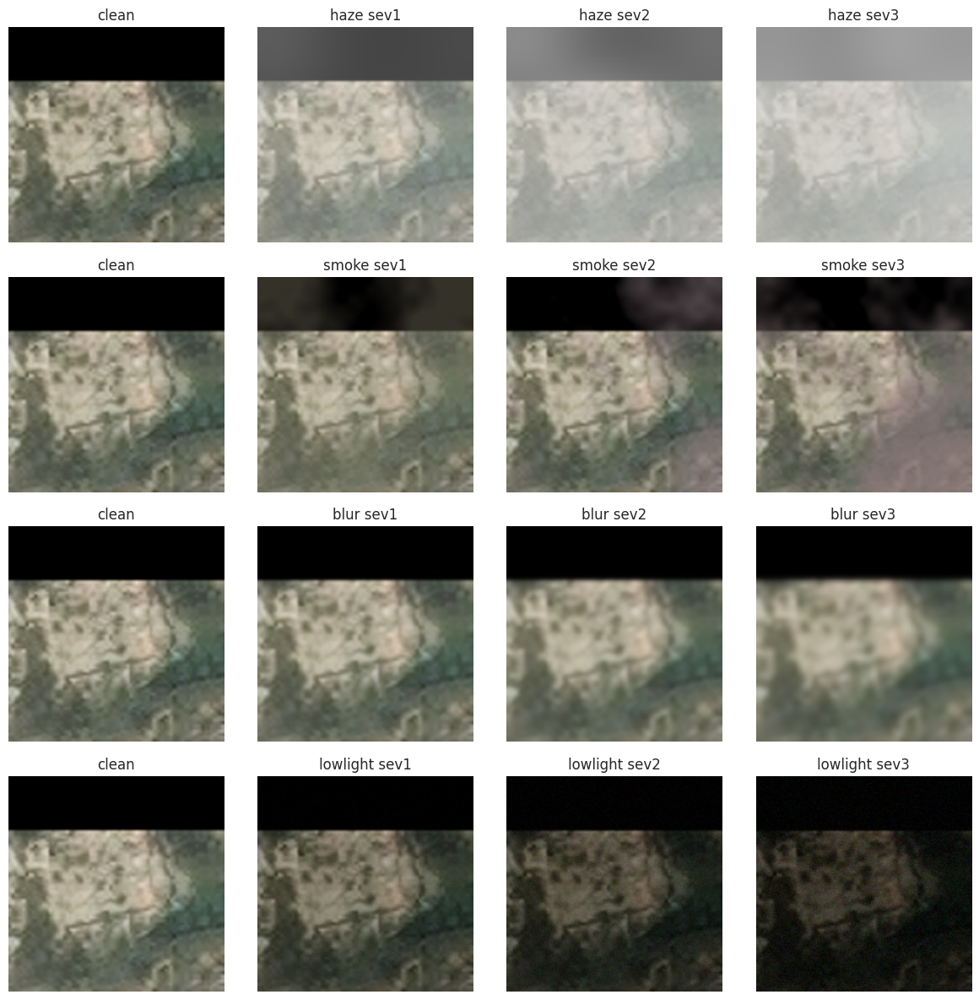

                  lap   dark  bright
kind     sev                        
0_clean  0     20.387  0.209   0.355
blur     1      7.835  0.217   0.356
         2      4.171  0.224   0.356
         3      3.105  0.230   0.356
haze     1     10.866  0.428   0.527
         2      5.875  0.574   0.641
         3      3.539  0.673   0.719
lowlight 1     72.164  0.101   0.221
         2    231.932  0.032   0.131
         3    447.177  0.007   0.075
smoke    1     15.882  0.254   0.386
         2     13.333  0.277   0.404
         3     11.029  0.300   0.422


In [ ]:
import zlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

DEG_SEED = 123
KINDS = ['haze', 'smoke', 'blur', 'lowlight']
P_MIXED = {'train': 0.4, 'val': 0.5, 'test': 0.5}   # share of degraded images in the "mixed" sets

def _rng(stem, kind, sev):
    """Deterministic RNG per (image, kind, severity): same input -> same degraded output, always."""
    return np.random.default_rng([DEG_SEED, zlib.crc32(stem.encode()), KINDS.index(kind), sev])

def smooth_noise(rng, size=224, octaves=4, base=4):
    """Fractal value noise in [0,1]: sum of upsampled random grids (cheap substitute for Perlin noise)."""
    out = np.zeros((size, size), np.float32); amp, tot = 1.0, 0.0
    for o in range(octaves):
        n = base * 2 ** o
        g = rng.random((n, n)).astype(np.float32)
        out += amp * cv2.resize(g, (size, size), interpolation=cv2.INTER_CUBIC)
        tot += amp; amp *= 0.5
    out /= tot
    return (out - out.min()) / (out.max() - out.min() + 1e-8)

# All functions take a float32 BGR image in [0,1] and return a float image.
def add_haze(img, rng, sev):
    """Atmospheric scattering model: I = J*t + A*(1-t), with t = exp(-beta*d)."""
    beta = {1: 0.5, 2: 1.0, 3: 1.5}[sev]
    d = 0.6 + 0.4 * smooth_noise(rng, octaves=2, base=2)     # pseudo scene depth in [0.6, 1.0]
    t = np.exp(-beta * d)[..., None]
    A = rng.uniform(0.80, 0.95)                               # atmospheric light
    return img * t + A * (1 - t)

def add_smoke(img, rng, sev):
    """Patchy semi-transparent grey-brown overlay (alpha varies spatially)."""
    amax = {1: 0.35, 2: 0.55, 3: 0.75}[sev]
    n = smooth_noise(rng, octaves=4, base=3)
    alpha = amax * np.clip((n - 0.25) / 0.5, 0, 1)[..., None]
    color = np.array([0.48, 0.52, 0.58]) + rng.uniform(-0.05, 0.05, 3)   # BGR order
    return img * (1 - alpha) + color.astype(np.float32) * alpha

def add_blur(img, rng, sev):
    """50% Gaussian blur (sigma 1/2/3), 50% linear motion blur (length 5/9/13, random angle)."""
    if rng.random() < 0.5:
        return cv2.GaussianBlur(img, (0, 0), {1: 1.0, 2: 2.0, 3: 3.0}[sev])
    L = {1: 5, 2: 9, 3: 13}[sev]
    k = np.zeros((L, L), np.float32); k[L // 2, :] = 1
    M = cv2.getRotationMatrix2D(((L - 1) / 2, (L - 1) / 2), rng.uniform(0, 180), 1.0)
    k = cv2.warpAffine(k, M, (L, L)); k /= k.sum()
    return cv2.filter2D(img, -1, k)

def add_lowlight(img, rng, sev):
    """Gamma + gain darkening plus sensor noise."""
    gamma = {1: 1.3, 2: 1.6, 3: 2.0}[sev]
    gain  = {1: 0.8, 2: 0.6, 3: 0.45}[sev]
    sig   = {1: 0.01, 2: 0.02, 3: 0.03}[sev]
    out = gain * np.power(np.clip(img, 0, 1), gamma)
    return out + rng.normal(0, sig, img.shape).astype(np.float32)

FUN = dict(haze=add_haze, smoke=add_smoke, blur=add_blur, lowlight=add_lowlight)

def degrade(img_bgr_u8, stem, kind, sev):
    rng = _rng(stem, kind, sev)
    y = FUN[kind](img_bgr_u8.astype(np.float32) / 255.0, rng, sev)
    return (np.clip(y, 0, 1) * 255 + 0.5).astype(np.uint8)

# ---------- Metadata: assign one (kind, severity) to every building, fixed seed ----------
meta = pd.read_csv(f'{OUT}/meta_clean.csv')
r = np.random.default_rng(DEG_SEED)
meta['kind'] = r.choice(KINDS, len(meta))
meta['sev'] = r.integers(1, 4, len(meta))
meta['in_mixed'] = r.random(len(meta)) < meta.split.map(P_MIXED)   # True => post image is degraded in the mixed set
print(meta.groupby('split').in_mixed.mean().round(3).to_dict(), '| rows:', len(meta))

# ---------- Visual check: one Destroyed crop, 4 kinds x 3 severities ----------
row = meta[(meta.split == 'train') & (meta.label == 3)].sample(1, random_state=3).iloc[0]
post = cv2.imread(f"{OUT}/crops/train/{row.stem}_post.jpg")
fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for i, k in enumerate(KINDS):
    ax[i, 0].imshow(post[..., ::-1]); ax[i, 0].set_title('clean'); ax[i, 0].axis('off')
    for s in (1, 2, 3):
        ax[i, s].imshow(degrade(post, row.stem, k, s)[..., ::-1])
        ax[i, s].set_title(f'{k} sev{s}'); ax[i, s].axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/eda/8_degradation_grid.png', dpi=120); plt.show()

# ---------- Quantitative check: do the quality proxies react to each degradation? ----------
def stats(im):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    return dict(lap=cv2.Laplacian(g, cv2.CV_64F).var(),                              # sharpness
                dark=cv2.erode(im.min(axis=2), np.ones((15, 15), np.uint8)).mean() / 255,  # haze proxy
                bright=g.mean() / 255)

rows = []
for stem, sp in meta[meta.split == 'val'].sample(300, random_state=0)[['stem', 'split']].values:
    im = cv2.imread(f'{OUT}/crops/{sp}/{stem}_post.jpg')
    rows.append(dict(kind='0_clean', sev=0, **stats(im)))
    for k in KINDS:
        for s in (1, 2, 3):
            rows.append(dict(kind=k, sev=s, **stats(degrade(im, stem, k, s))))
print(pd.DataFrame(rows).groupby(['kind', 'sev']).mean().round(3))

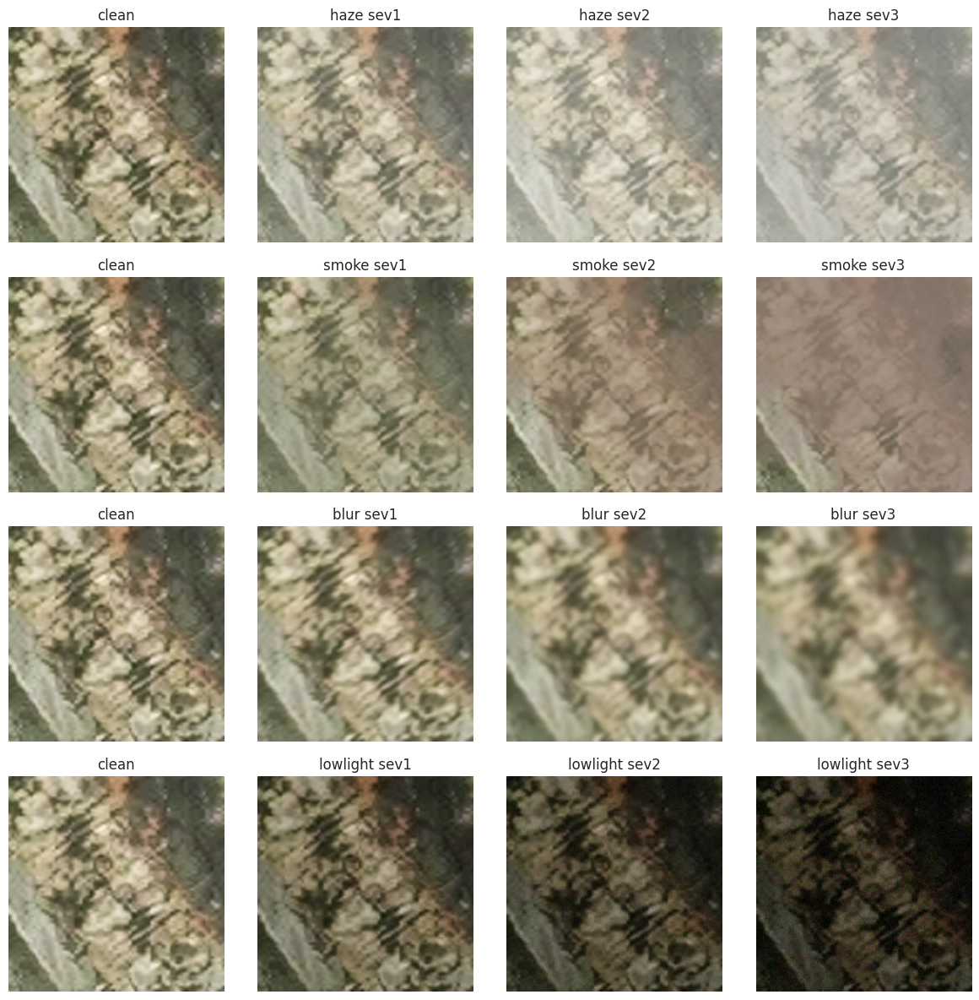

                  lap  lap_s   dark  bright
kind     sev                               
0_clean  0     15.277  3.936  0.222   0.371
blur     1      6.405  3.232  0.229   0.371
         2      4.153  2.557  0.237   0.371
         3      3.225  2.121  0.243   0.371
haze     1     11.716  3.058  0.361   0.479
         2      9.379  2.505  0.468   0.562
         3      8.532  2.058  0.581   0.650
lowlight 1     70.769  3.231  0.107   0.229
         2    237.509  2.660  0.033   0.135
         3    461.170  2.392  0.007   0.077
smoke    1     10.299  2.846  0.293   0.417
         2      8.303  2.441  0.327   0.440
         3      7.581  2.122  0.355   0.461


In [ ]:
# ---- Updated degradation functions (same names; FUN is rebuilt at the bottom) ----
def add_haze(img, rng, sev):
    """Atmospheric scattering: I = J*t + A*(1-t), t = exp(-beta*d). Milder beta than before."""
    beta = {1: 0.3, 2: 0.6, 3: 1.0}[sev]
    d = 0.6 + 0.4 * smooth_noise(rng, octaves=2, base=2)     # pseudo scene depth in [0.6, 1.0]
    t = np.exp(-beta * d)[..., None]
    A = rng.uniform(0.80, 0.95)
    return img * t + A * (1 - t)

def add_smoke(img, rng, sev):
    """Patchy grey-brown smoke; larger coverage than before so it actually affects the building."""
    amax = {1: 0.40, 2: 0.60, 3: 0.80}[sev]
    n = smooth_noise(rng, octaves=4, base=3)
    alpha = amax * np.clip((n - 0.10) / 0.50, 0, 1)[..., None]
    color = np.array([0.48, 0.52, 0.58]) + rng.uniform(-0.05, 0.05, 3)   # BGR
    return img * (1 - alpha) + color.astype(np.float32) * alpha

FUN = dict(haze=add_haze, smoke=add_smoke, blur=add_blur, lowlight=add_lowlight)

def degrade(img_bgr_u8, stem, kind, sev):
    """Degrade a uint8 BGR crop; no-data (black) pixels are restored so they stay black."""
    rng = _rng(stem, kind, sev)
    f = img_bgr_u8.astype(np.float32) / 255.0
    valid = (img_bgr_u8.max(axis=2) > 6)[..., None]          # False on zero-padded / no-data pixels
    y = np.clip(FUN[kind](f, rng, sev), 0, 1)
    y = np.where(valid, y, f)
    return (y * 255 + 0.5).astype(np.uint8)

# ---- Visual check on a crop WITHOUT black regions ----
cand = meta[(meta.split == 'train') & (meta.label == 3) & (meta.black_max < 0.01)]
row = cand.sample(1, random_state=5).iloc[0]
post = cv2.imread(f"{OUT}/crops/train/{row.stem}_post.jpg")
fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for i, k in enumerate(KINDS):
    ax[i, 0].imshow(post[..., ::-1]); ax[i, 0].set_title('clean'); ax[i, 0].axis('off')
    for s in (1, 2, 3):
        ax[i, s].imshow(degrade(post, row.stem, k, s)[..., ::-1])
        ax[i, s].set_title(f'{k} sev{s}'); ax[i, s].axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/eda/8_degradation_grid_v2.png', dpi=120); plt.show()

# ---- Quantitative check (crops without black regions only) ----
def stats(im):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    gs = cv2.GaussianBlur(g, (0, 0), 1.5)                    # light smoothing -> noise-robust sharpness
    return dict(lap=cv2.Laplacian(g, cv2.CV_64F).var(),
                lap_s=cv2.Laplacian(gs, cv2.CV_64F).var(),
                dark=cv2.erode(im.min(axis=2), np.ones((15, 15), np.uint8)).mean() / 255,
                bright=g.mean() / 255)

rows = []
sub = meta[(meta.split == 'val') & (meta.black_max < 0.01)].sample(300, random_state=0)
for stem, sp in sub[['stem', 'split']].values:
    im = cv2.imread(f'{OUT}/crops/{sp}/{stem}_post.jpg')
    rows.append(dict(kind='0_clean', sev=0, **stats(im)))
    for k in KINDS:
        for s in (1, 2, 3):
            rows.append(dict(kind=k, sev=s, **stats(degrade(im, stem, k, s))))
print(pd.DataFrame(rows).groupby(['kind', 'sev']).mean().round(3))

In [ ]:
import shutil

DEG = f'{OUT}/crops_deg'
shutil.rmtree(DEG, ignore_errors=True)
for sp in ['train', 'val', 'test']:
    os.makedirs(f'{DEG}/{sp}', exist_ok=True)

def make_one(args):
    """Degrade one post crop with its fixed (kind, severity) and save it."""
    sp, stem, kind, sev = args
    im = cv2.imread(f'{OUT}/crops/{sp}/{stem}_post.jpg')
    cv2.imwrite(f'{DEG}/{sp}/{stem}_post.jpg', degrade(im, stem, kind, int(sev)),
                [cv2.IMWRITE_JPEG_QUALITY, 95])
    return 1

jobs = list(zip(meta.split, meta.stem, meta.kind, meta.sev))
with ProcessPoolExecutor(os.cpu_count()) as ex:
    n = sum(tqdm(ex.map(make_one, jobs, chunksize=64), total=len(jobs)))
print('degraded crops:', n, '/', len(meta))

# Determinism check: same input must give byte-identical output
r0 = meta.iloc[0]
im0 = cv2.imread(f'{OUT}/crops/{r0.split}/{r0.stem}_post.jpg')
assert np.array_equal(degrade(im0, r0.stem, r0.kind, int(r0.sev)),
                      degrade(im0, r0.stem, r0.kind, int(r0.sev))), 'degradation is not deterministic!'

# Save metadata (kind / sev / in_mixed columns) and back up to Drive
meta.to_csv(f'{OUT}/meta_deg.csv', index=False)
!tar -cf {ROOT}/crops_deg.tar -C {OUT} crops_deg
!cp {OUT}/meta_deg.csv {ROOT}/
!ls -lh {ROOT}

# Composition of the degraded sets (test: how many images per kind x severity)
print(pd.crosstab(meta[meta.split == 'test'].kind, meta[meta.split == 'test'].sev))
print('degraded share in mixed sets:', meta.groupby('split').in_mixed.mean().round(3).to_dict())

  0%|          | 0/54457 [00:00<?, ?it/s]

degraded crops: 54457 / 54457
total 1.9G
-rw------- 1 root root  26M Oct 10 16:54 buildings_all.csv
-rw------- 1 root root 622M Oct 10 17:43 crops_deg.tar
-rw------- 1 root root 1.3G Oct 10 17:24 crops.tar
drwx------ 2 root root 4.0K Oct 10 17:32 eda
-rw------- 1 root root  14M Oct 10 17:24 meta_clean.csv
-rw------- 1 root root  14M Oct 10 17:24 meta.csv
-rw------- 1 root root  14M Oct 10 17:43 meta_deg.csv
sev          1     2     3
kind                      
blur      1451  1548  1554
haze      1461  1513  1553
lowlight  1506  1483  1443
smoke     1456  1489  1482
degraded share in mixed sets: {'test': 0.491, 'train': 0.403, 'val': 0.501}


In [ ]:
# Raw xBD tiles are no longer needed; all crops are final and backed up on Drive
!rm -rf /content/xbd
!df -h /content | tail -1

overlay         113G   47G   67G  42% /


In [ ]:
from sklearn.metrics import roc_auc_score

# 3000 test buildings without black regions: compare CLEAN vs DEGRADED version of the same building
sub = meta[(meta.split == 'test') & (meta.black_max < 0.01)].sample(3000, random_state=0)

def both(stem):
    c = stats(cv2.imread(f'{OUT}/crops/test/{stem}_post.jpg'))
    d = stats(cv2.imread(f'{DEG}/test/{stem}_post.jpg'))
    return c, d

with ProcessPoolExecutor(os.cpu_count()) as ex:
    res = list(tqdm(ex.map(both, sub.stem.tolist(), chunksize=32), total=len(sub)))

C = pd.DataFrame([r[0] for r in res]); D = pd.DataFrame([r[1] for r in res])
for X in (C, D):
    X[['kind', 'sev']] = sub[['kind', 'sev']].values
b0 = C.bright.median()                                   # typical clean brightness

P = pd.concat([C.assign(y=0), D.assign(y=1)], ignore_index=True)   # y=1 means degraded

# Candidate degradation scores; higher = more degraded
S = pd.DataFrame({
    '-lap':       -P.lap,                  # raw sharpness (expected to fail on low-light)
    '-lap_s':     -P.lap_s,                # smoothed, noise-robust sharpness
    'dark':        P.dark,                 # haze proxy (dark-channel mean)
    '|dbright|':  (P.bright - b0).abs(),   # deviation from typical brightness
})
S['G_combined'] = S[['-lap_s', 'dark', '|dbright|']].rank(pct=True).mean(axis=1)

rows = []
for (k, s), g in P.groupby(['kind', 'sev']):
    rows.append(dict(kind=k, sev=s, **{c: roc_auc_score(g.y, S.loc[g.index, c]) for c in S.columns}))
print(pd.DataFrame(rows).round(2).set_index(['kind', 'sev']))

  0%|          | 0/3000 [00:00<?, ?it/s]

              -lap  -lap_s  dark  |dbright|  G_combined
kind     sev                                           
blur     1    0.67    0.60  0.53       0.50        0.58
         2    0.87    0.80  0.56       0.50        0.72
         3    0.91    0.90  0.60       0.50        0.82
haze     1    0.59    0.66  0.97       0.81        0.95
         2    0.69    0.78  1.00       0.98        0.99
         3    0.82    0.92  1.00       0.99        1.00
lowlight 1    0.04    0.63  0.03       0.93        0.68
         2    0.00    0.76  0.00       0.99        0.79
         3    0.00    0.83  0.00       1.00        0.87
smoke    1    0.64    0.71  0.82       0.49        0.79
         2    0.72    0.78  0.94       0.59        0.92
         3    0.82    0.90  0.96       0.79        0.97


In [ ]:
%%writefile /content/drive/MyDrive/hawkeye/hawkeye_lib.py
"""HawkEye shared library: data, model, loss, training, evaluation."""
import os, math, random, time
import numpy as np, pandas as pd, cv2, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score
from tqdm.auto import tqdm
from transformers import AutoModel

OUT  = '/content/hawkeye'
ROOT = '/content/drive/MyDrive/hawkeye'
NAMES = ['No', 'Minor', 'Major', 'Destroyed']
DEV = 'cuda'
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1) * 255   # ImageNet stats (DINOv2 default)
_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1) * 255

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def load_meta():
    """meta_deg.csv: one row per building (split, stem, label, disaster, kind, sev, in_mixed, ...)."""
    return pd.read_csv(f'{OUT}/meta_deg.csv')

def prep(x):
    """uint8 (B,3,H,W) on CPU -> normalised float on GPU."""
    return (x.to(DEV, non_blocking=True).float() - _MEAN.to(DEV)) / _STD.to(DEV)

# ----------------------------------------------------------------------------- data
class PairDS(Dataset):
    """Returns (pre, post, label, idx). mode: 'clean' | 'degraded' | 'mixed' (degraded only where in_mixed)."""
    def __init__(self, df, mode='mixed', train=False):
        assert mode in ('clean', 'degraded', 'mixed')
        self.df = df.reset_index(drop=True)
        self.sp, self.stem = self.df['split'].values, self.df['stem'].values
        self.y = self.df['label'].values.astype(np.int64)
        self.mixed = self.df['in_mixed'].values.astype(bool)
        self.mode, self.train = mode, train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        sp, st = self.sp[i], self.stem[i]
        deg = self.mode == 'degraded' or (self.mode == 'mixed' and self.mixed[i])
        pre  = cv2.imread(f'{OUT}/crops/{sp}/{st}_pre.jpg')[..., ::-1]                       # BGR -> RGB
        post = cv2.imread(f"{OUT}/{'crops_deg' if deg else 'crops'}/{sp}/{st}_post.jpg")[..., ::-1]
        if self.train:                                   # SAME geometric transform on pre and post
            k, fl = random.randint(0, 3), random.random() < 0.5
            pre, post = np.rot90(pre, k), np.rot90(post, k)
            if fl:
                pre, post = pre[:, ::-1], post[:, ::-1]
        t = lambda a: torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1)
        return t(pre), t(post), int(self.y[i]), i

# ----------------------------------------------------------------------------- model
class SiameseCrossViT(nn.Module):
    """Shared DINOv2 backbone on pre/post; cross-attention (Q=post, K/V=pre);
    fuse = [f_post, f_post - f_pre, f_cross]; MLP head -> 4 logits; extra head -> log sigma^2 (aleatoric)."""
    def __init__(self, name='facebook/dinov2-base', unfreeze_last=2, n_cls=4, drop=0.3, heads=8):
        super().__init__()
        self.bb = AutoModel.from_pretrained(name)
        for p in self.bb.parameters():
            p.requires_grad = False
        if unfreeze_last > 0:                            # fine-tune only the last blocks (+ final norm)
            for blk in self.bb.encoder.layer[-unfreeze_last:]:
                for p in blk.parameters():
                    p.requires_grad = True
            for p in self.bb.layernorm.parameters():
                p.requires_grad = True
        D = self.bb.config.hidden_size
        self.nq, self.nkv = nn.LayerNorm(D), nn.LayerNorm(D)
        self.cross = nn.MultiheadAttention(D, heads, dropout=0.1, batch_first=True)
        self.drop = nn.Dropout(drop)
        self.head = nn.Sequential(nn.Linear(3 * D, 512), nn.GELU(), nn.Dropout(drop), nn.Linear(512, n_cls))
        self.var_head = nn.Sequential(nn.Linear(3 * D, 128), nn.GELU(), nn.Linear(128, 1))
    def forward(self, pre, post, return_feat=False):
        B = pre.size(0)
        h = self.bb(pixel_values=torch.cat([pre, post], 0)).last_hidden_state   # one pass, shared weights
        hp, hq = h[:B], h[B:]                                                   # token 0 = CLS
        kv = self.nkv(hp[:, 1:])
        att, _ = self.cross(self.nq(hq[:, 1:]), kv, kv, need_weights=False)
        fuse = torch.cat([hq[:, 0], hq[:, 0] - hp[:, 0], att.mean(1)], 1)
        logits, log_var = self.head(self.drop(fuse)), self.var_head(fuse)
        return (logits, log_var, fuse) if return_feat else (logits, log_var)

# ----------------------------------------------------------------------------- loss
def cb_weights(counts, beta=0.999):
    """Class-balanced weights (1-beta)/(1-beta^n), normalised to sum to n_classes."""
    n = np.maximum(np.asarray(counts, dtype=float), 1)
    w = (1 - beta) / (1 - beta ** n)
    return torch.tensor(w / w.sum() * len(n), dtype=torch.float32)

def hawkeye_loss(logits, log_var, y, w, gamma=2.0, alpha=0.5, T=5):
    """Class-balanced focal + alpha * ordinal (squared distance of expected class).
    Aleatoric part (Kendall & Gal): logits are perturbed with N(0, sigma^2) noise, T samples, probs averaged."""
    sigma = torch.exp(0.5 * log_var.clamp(-6, 3))                      # (B,1)
    eps = torch.randn(T, *logits.shape, device=logits.device)
    p = F.softmax(logits.unsqueeze(0) + sigma.unsqueeze(0) * eps, -1).mean(0)
    pt = p.gather(1, y[:, None]).squeeze(1).clamp_min(1e-8)
    focal = (w[y] * (1 - pt) ** gamma * (-pt.log())).mean()
    cls = torch.arange(p.size(1), device=p.device).float()
    ordinal = (((p * cls).sum(1) - y.float()) ** 2).mean()
    return focal + alpha * ordinal

# ----------------------------------------------------------------------------- eval
@torch.no_grad()
def predict(model, ds, bs=64, workers=2):
    model.eval()
    dl = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=workers, pin_memory=True)
    P, LV = [], []
    for pre, post, _, _ in dl:
        with torch.autocast('cuda', dtype=torch.float16):
            lg, lv = model(prep(pre), prep(post))
        P.append(F.softmax(lg.float(), -1).cpu()); LV.append(lv.float().cpu())
    return torch.cat(P).numpy(), torch.cat(LV).squeeze(1).numpy()

def metrics(y, P):
    """Severe = Major + Destroyed (classes 2,3). sev_recall is the headline metric."""
    y = np.asarray(y); pred = np.asarray(P).argmax(1)
    st, sp_ = y >= 2, pred >= 2
    tp = float((st & sp_).sum())
    rec, prec = tp / max(st.sum(), 1), tp / max(sp_.sum(), 1)
    return dict(n=int(len(y)), n_sev=int(st.sum()),
                macro_f1=float(f1_score(y, pred, labels=[0, 1, 2, 3], average='macro', zero_division=0)),
                f1=[float(v) for v in f1_score(y, pred, labels=[0, 1, 2, 3], average=None, zero_division=0)],
                sev_recall=float(rec), sev_prec=float(prec),
                sev_f1=float(2 * prec * rec / max(prec + rec, 1e-8)),
                destroyed_recall=float(((y == 3) & (pred == 3)).sum() / max((y == 3).sum(), 1)))

def evaluate_suite(model, va, te, bs=64):
    """Val (mixed) + test (clean / degraded / mixed). Returns (metrics dict, {name: (probs, log_var)})."""
    res, preds = {}, {}
    for name, df, mode in [('val_mixed', va, 'mixed'), ('test_clean', te, 'clean'),
                           ('test_degraded', te, 'degraded'), ('test_mixed', te, 'mixed')]:
        P, LV = predict(model, PairDS(df, mode), bs)
        res[name], preds[name] = metrics(df['label'].values, P), (P, LV)
    return res, preds

# ----------------------------------------------------------------------------- train
def train_model(train_df, val_df, cfg, tag, workers=2):
    seed_all(cfg['seed'])
    model = SiameseCrossViT(cfg['model'], cfg['unfreeze_last']).to(DEV)
    w = cb_weights(np.bincount(train_df['label'].values, minlength=4), cfg['beta']).to(DEV)
    print('class-balanced weights:', [round(float(v), 3) for v in w.cpu()])
    dl = DataLoader(PairDS(train_df, 'mixed', True), batch_size=cfg['bs'], shuffle=True, drop_last=True,
                    num_workers=workers, pin_memory=True, persistent_workers=workers > 0)
    names = [n for n, p in model.named_parameters() if p.requires_grad]
    bb_p   = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith('bb.')]
    head_p = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith('bb.')]
    groups = [g for g in [dict(params=head_p, lr=cfg['lr_head'], weight_decay=cfg['wd']),
                          dict(params=bb_p,   lr=cfg['lr_bb'],   weight_decay=cfg['wd'])] if g['params']]
    opt = torch.optim.AdamW(groups)
    total = cfg['epochs'] * len(dl); warm = max(1, int(0.05 * total))          # 5% warmup, then cosine
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.cuda.amp.GradScaler()
    allp = [p for g in groups for p in g['params']]
    ckpt, best, bad, hist = f'{ROOT}/ckpt_{tag}.pt', -1.0, 0, []
    for ep in range(cfg['epochs']):
        model.train(); t0 = time.time(); run = n = 0
        for pre, post, y, _ in tqdm(dl, leave=False):
            y = y.to(DEV)
            with torch.autocast('cuda', dtype=torch.float16):
                lg, lv = model(prep(pre), prep(post))
            loss = hawkeye_loss(lg.float(), lv.float(), y, w, cfg['gamma'], cfg['alpha'])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(allp, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(y); n += len(y)
        m = metrics(val_df['label'].values, predict(model, PairDS(val_df, 'mixed'))[0])
        hist.append(dict(epoch=ep + 1, loss=run / n, **{k: m[k] for k in ('macro_f1', 'sev_recall', 'sev_prec', 'sev_f1')}))
        print(f"ep {ep+1}/{cfg['epochs']} loss {run/n:.4f} | val sevF1 {m['sev_f1']:.3f} sevRecall {m['sev_recall']:.3f} "
              f"macroF1 {m['macro_f1']:.3f} | {time.time()-t0:.0f}s")
        if m['sev_f1'] > best:                           # early stopping on severe-F1 (val Minor is too small for macro-F1)
            best, bad = m['sev_f1'], 0
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items() if k in names}, ckpt)
        else:
            bad += 1
            if bad >= cfg['patience']:
                print('early stop'); break
    model.load_state_dict(torch.load(ckpt), strict=False)   # restore best trainable weights
    return model, hist

Writing /content/drive/MyDrive/hawkeye/hawkeye_lib.py
